# PCA of LFP band envelopes: a simpler route to motifs?

Mouse 720762, deep prelimbic LFP (PL5, probe F), stimulation-free data, for the awake, isoflurane and full
windows. Instead of Mishler's sign-binarizing and hierarchical clustering, this runs PCA directly on the
z-scored band envelopes, one timepoint per second. A principal component is a pattern across bands, and its two
ends (+ and -) are a natural motif and opponent.

Bands and preprocessing are the same as our earlier motif analysis, so the results are directly comparable.

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src import session_data as sd
from src.state_motifs import BANDS, COLORS, FS, WINDOWS, band_labels, envelope_pieces, restrict, zscore
%matplotlib inline

REPO = Path.cwd().resolve().parents[2]
NWB = REPO / "data" / "raw" / "720762-20240221-v001.nwb"
RESULTS = REPO / "data" / "out" / "2026-11-01_mouse720762" / "results.json"
PROBE, REGION = "probeF", "PL5"
labels = band_labels()
x_bands = np.arange(len(BANDS))

## Load the LFP and compute band envelopes

In [2]:
io, nwb = sd.open_nwb(NWB)
info = sd.read_info(nwb, NWB.name)
segments, windows = sd.stim_free_segments(info), sd.analysis_windows(info)
channel = sd.lfp_channel(nwb, PROBE, REGION)
t, x, fs = sd.decimate(*sd.read_raw(nwb, ("lfp", PROBE, channel)), FS)
rs = nwb.processing["behavior"]["BehavioralTimeSeries"]["running_speed"]
speed = rs.data[:]
speed_t = rs.timestamps[:] if rs.timestamps is not None else rs.starting_time + np.arange(speed.size) / rs.rate
io.close()
hop = int(round(fs))
pieces = envelope_pieces(t, x, fs, segments)

def window_data(pieces, win):
    """One row per second: z-scored band envelopes in this window, and their times."""
    z = zscore(restrict(pieces, windows[win], fs))
    return np.concatenate([p.t[::hop] for p in z]), np.concatenate([p.env[::hop] for p in z])

data = {w: window_data(pieces, w) for w in WINDOWS}
print(f"{REGION} channel {channel}, {fs:.0f} Hz")
pd.DataFrame({w: {"seconds": v[1].shape[0], "bands": v[1].shape[1]} for w, v in data.items()})

PL5 channel 254, 250 Hz


,awake,isoflurane,full
seconds,1537,1973,3688
bands,10,10,10


## PCA on the centered timepoints

In [3]:
def pca(X):
    Xc = X - X.mean(axis=0)
    _, s, vt = np.linalg.svd(Xc, full_matrices=False)
    vt = vt * np.sign(vt[np.arange(vt.shape[0]), np.abs(vt).argmax(axis=1)])[:, None]
    return vt, Xc @ vt.T, s ** 2 / (s ** 2).sum()

fits = {w: pca(v[1]) for w, v in data.items()}
pd.DataFrame({w: f[2][:4] for w, f in fits.items()}, index=["PC1", "PC2", "PC3", "PC4"]).round(3)

,awake,isoflurane,full
PC1,0.364,0.824,0.621
PC2,0.141,0.092,0.251
PC3,0.109,0.039,0.049
PC4,0.099,0.017,0.038


## Every second projected onto PC1 and PC2, with what each PC means

Left: each dot is one second. Middle and right: the band pattern of each PC. A positive score means the second looks like the plotted pattern; a negative score means it looks like its mirror image.

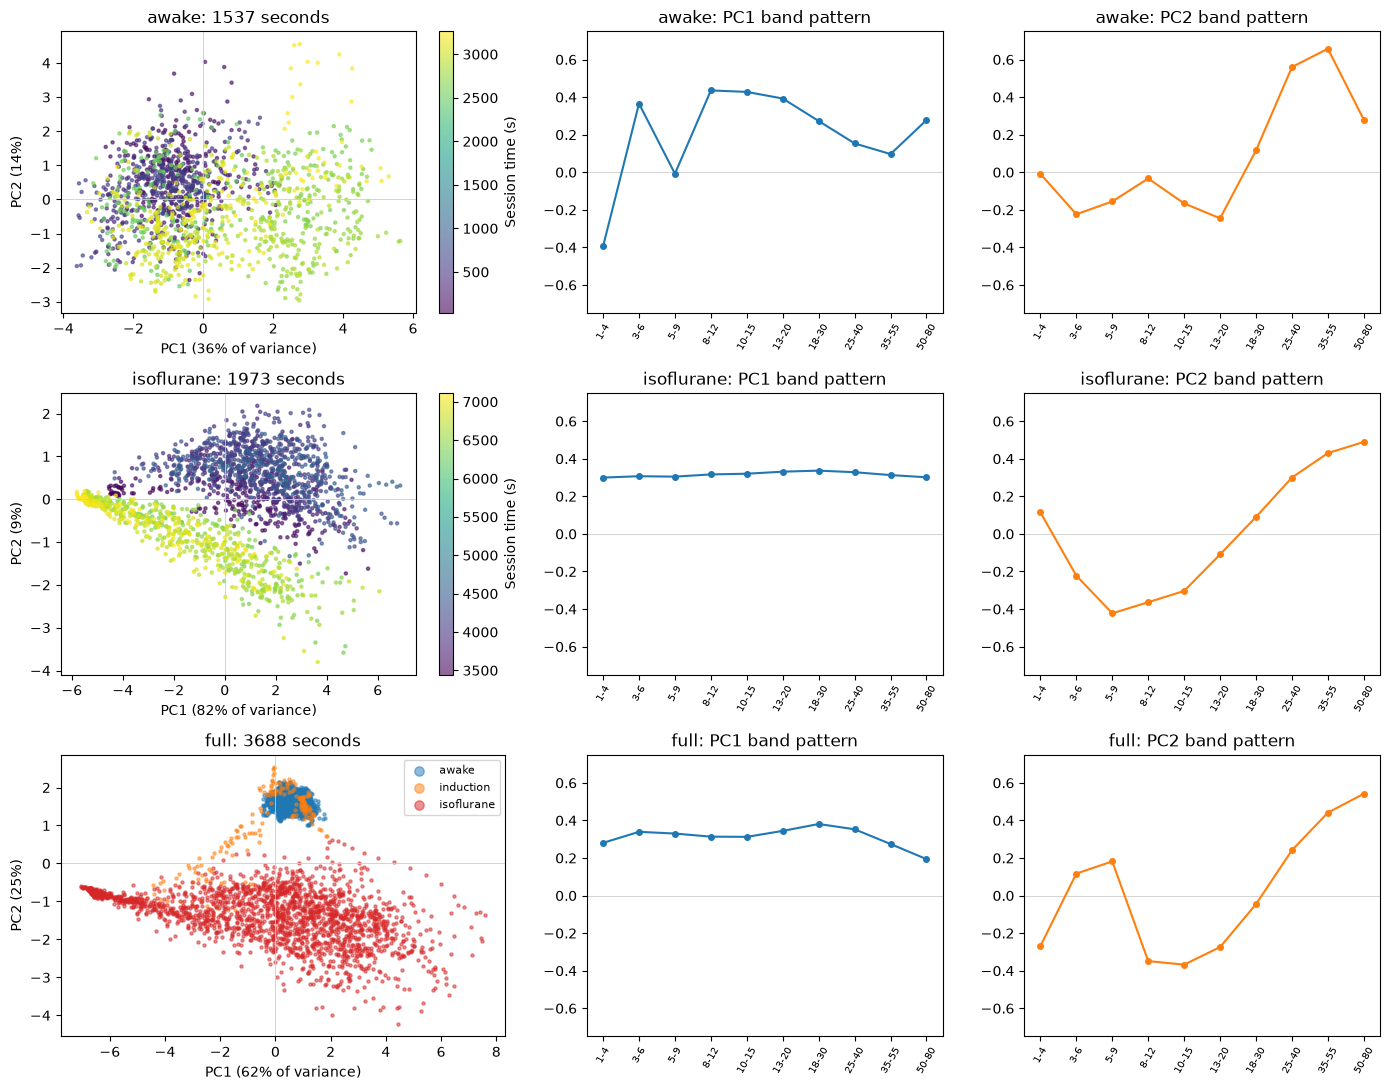

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11), gridspec_kw={"width_ratios": [1.25, 1, 1]})
for row, win in zip(axes, WINDOWS):
    tt = data[win][0]
    vt, scores, var = fits[win]
    if win == "full":
        state = sd.state_of_time(tt, info)
        for name in ("awake", "induction", "isoflurane"):
            k = state == name
            row[0].scatter(scores[k, 0], scores[k, 1], s=5, alpha=0.5, color=COLORS[name], label=name)
        row[0].legend(markerscale=3, fontsize=8)
    else:
        im = row[0].scatter(scores[:, 0], scores[:, 1], s=5, alpha=0.6, c=tt, cmap="viridis")
        fig.colorbar(im, ax=row[0], label="Session time (s)")
    row[0].axhline(0, color="0.8", lw=0.6); row[0].axvline(0, color="0.8", lw=0.6)
    row[0].set_xlabel(f"PC1 ({var[0]:.0%} of variance)"); row[0].set_ylabel(f"PC2 ({var[1]:.0%})")
    row[0].set_title(f"{win}: {scores.shape[0]} seconds")
    for ax, i in zip(row[1:], (0, 1)):
        ax.axhline(0, color="0.8", lw=0.6)
        ax.plot(x_bands, vt[i], "-o", ms=4, color=f"C{i}")
        ax.set_xticks(x_bands, labels, rotation=60, fontsize=7)
        ax.set_ylim(-0.75, 0.75)
        ax.set_title(f"{win}: PC{i + 1} band pattern")
fig.tight_layout()

## Are the PCs fast fluctuations, or slow differences between parts of the session?

The colours above suggest time matters. Here are the scores over time, with running speed (awake) and the isoflurane level.

awake PC1 vs running speed: r = 0.23
awake PC2 vs running speed: r = -0.11


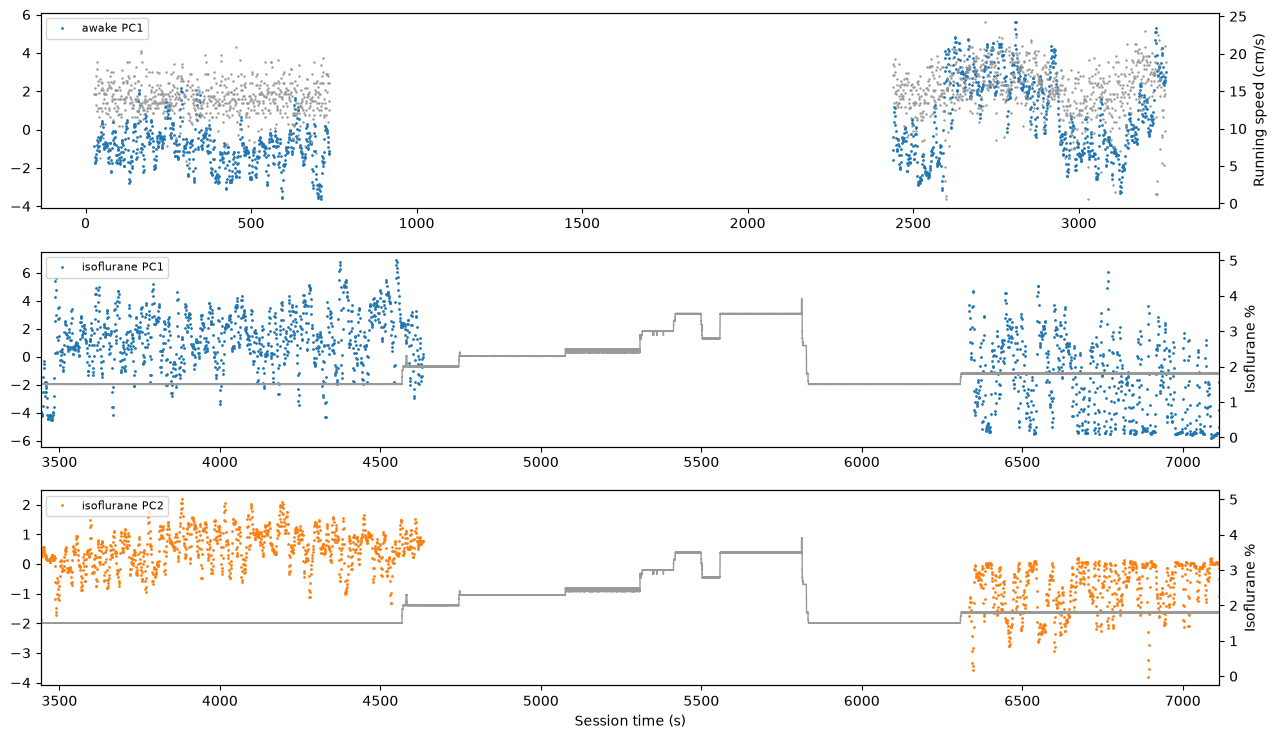

In [5]:
def smooth(v, n=5):
    return np.convolve(v, np.ones(n) / n, mode="same")

fig, axes = plt.subplots(3, 1, figsize=(13, 7.5))
tt, sc = data["awake"][0], fits["awake"][1]
run = np.interp(tt, speed_t, smooth(speed, 50))
axes[0].plot(tt, sc[:, 0], ".", ms=2, color="C0", label="awake PC1")
ax2 = axes[0].twinx(); ax2.plot(tt, run, ".", ms=1.5, color="0.6"); ax2.set_ylabel("Running speed (cm/s)")
axes[0].legend(loc="upper left", fontsize=8)
tt_i, sc_i = data["isoflurane"][0], fits["isoflurane"][1]
for ax, i in zip(axes[1:], (0, 1)):
    ax.plot(tt_i, sc_i[:, i], ".", ms=2, color=f"C{i}", label=f"isoflurane PC{i + 1}")
    ax2 = ax.twinx(); ax2.plot(info.iso_t, info.iso_level, color="0.6", lw=1); ax2.set_ylabel("Isoflurane %")
    ax.set_xlim(tt_i[0], tt_i[-1]); ax.legend(loc="upper left", fontsize=8)
axes[-1].set_xlabel("Session time (s)")
fig.tight_layout()
print(f"awake PC1 vs running speed: r = {np.corrcoef(sc[:, 0], run)[0, 1]:.2f}")
print(f"awake PC2 vs running speed: r = {np.corrcoef(sc[:, 1], run)[0, 1]:.2f}")

## Do the patterns survive within each stretch?

Each window is made of separate stimulation-free stretches. Z-scoring every stretch on its own removes differences between stretches, leaving only moment-to-moment fluctuations. The baseline is phase-randomized LFP, treated the same way: same power spectrum, but no real timing relationships between frequencies, so it shows what PCA finds from band overlap and chance alone.

In [6]:
rng = np.random.default_rng(0)

def stretches(win):
    a, b = windows[win]
    return [(max(a, s0), min(b, s1)) for s0, s1 in segments if min(b, s1) - max(a, s0) > 120]

def per_stretch(trace, win):
    ps = [zscore([p])[0] for p in envelope_pieces(t, trace, fs, stretches(win))]
    return np.concatenate([p.env[::hop] for p in ps])

def surrogate(win):
    y = x.copy()
    for a, b in stretches(win):
        k = (t >= a) & (t < b)
        spectrum = np.fft.rfft(x[k])
        phases = np.exp(2j * np.pi * rng.random(spectrum.size)); phases[0] = 1
        y[k] = np.fft.irfft(np.abs(spectrum) * phases, n=int(k.sum()))
    return y

within = {w: pca(per_stretch(x, w)) for w in ("awake", "isoflurane")}
sur = {w: np.array([pca(per_stretch(surrogate(w), w))[2][:3] for _ in range(5)]) for w in within}
print("stretches:", {w: [(round(a), round(b)) for a, b in stretches(w)] for w in within})
pd.DataFrame({w: {"within-stretch PC1": within[w][2][0], "surrogate PC1": sur[w][:, 0].mean(),
                  "within-stretch PC2": within[w][2][1], "surrogate PC2": sur[w][:, 1].mean(),
                  "within-stretch PC3": within[w][2][2], "surrogate PC3": sur[w][:, 2].mean()} for w in within}).round(3)

stretches: {'awake': [(17, 747), (2428, 3264)], 'isoflurane': [(3442, 4643), (6324, 7124)]}


,awake,isoflurane
within-stretch PC1,0.307,0.819
surrogate PC1,0.165,0.159
within-stretch PC2,0.124,0.074
surrogate PC2,0.151,0.142
within-stretch PC3,0.115,0.043
surrogate PC3,0.134,0.127


,awake,isoflurane
PC1,0.99,1.00
PC2,0.81,0.62
PC3,0.83,0.66


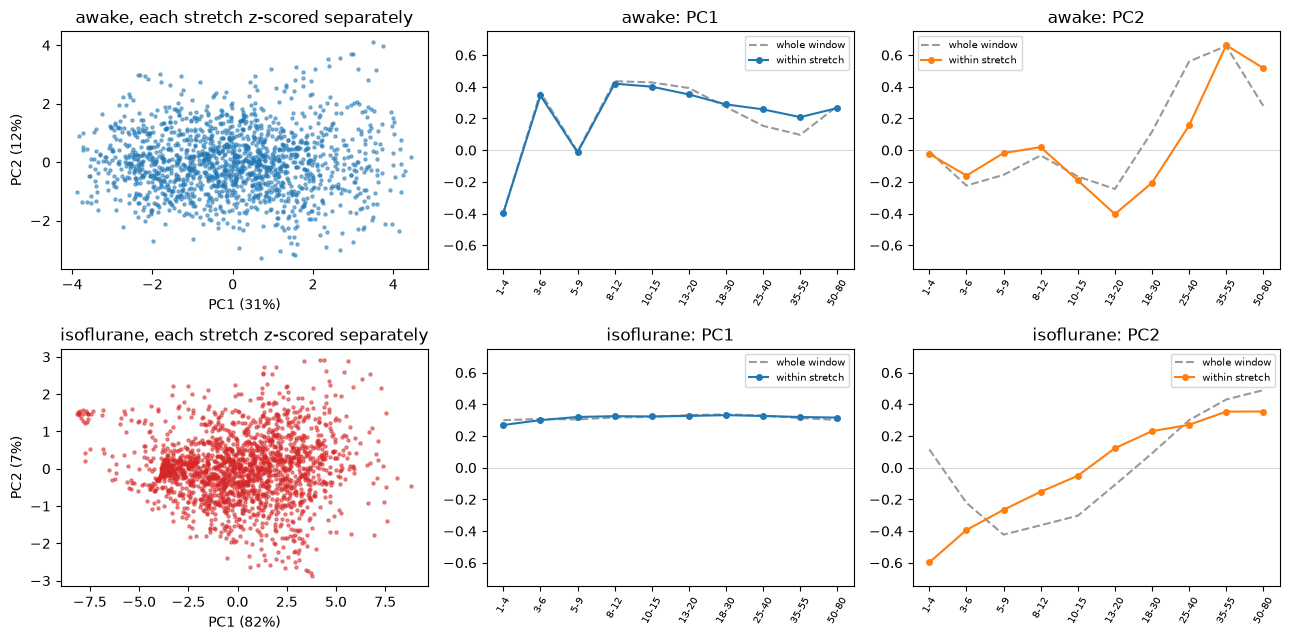

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for row, win in zip(axes, within):
    vt, sc, var = within[win]
    row[0].scatter(sc[:, 0], sc[:, 1], s=5, alpha=0.5, color=COLORS[win])
    row[0].set_xlabel(f"PC1 ({var[0]:.0%})"); row[0].set_ylabel(f"PC2 ({var[1]:.0%})")
    row[0].set_title(f"{win}, each stretch z-scored separately")
    for ax, i in zip(row[1:], (0, 1)):
        ax.axhline(0, color="0.8", lw=0.6)
        ax.plot(x_bands, fits[win][0][i], "--", color="0.6", label="whole window")
        sign = np.sign(vt[i] @ fits[win][0][i]) or 1
        ax.plot(x_bands, sign * vt[i], "-o", ms=4, color=f"C{i}", label="within stretch")
        ax.set_xticks(x_bands, labels, rotation=60, fontsize=7); ax.set_ylim(-0.75, 0.75)
        ax.set_title(f"{win}: PC{i + 1}"); ax.legend(fontsize=7)
fig.tight_layout()
pd.DataFrame({w: {f"PC{i + 1}": abs(within[w][0][i] @ fits[w][0][i]) for i in range(3)} for w in within}).round(2)

## Do the PCs match the motifs we already found?

|r| between each PC's band pattern and the motif from the same window (sign is arbitrary). Then whether awake and isoflurane share their PCs.

In [8]:
R = json.loads(RESULTS.read_text().replace("NaN", "null"))
rows = []
for win in WINDOWS:
    for ver in ("strict", "relaxed"):
        run = next(r for r in R["motif_runs"] if r["signal"] == "lfp_PL5" and r["window"] == win and r["version"] == ver)
        if run["n_motifs"]:
            motif = np.array(run["motifs"])[:, 0]
            rows.append({"window": win, "motif from": ver,
                         **{f"|r| with PC{i + 1}": abs(np.corrcoef(motif, fits[win][0][i])[0, 1]) for i in range(3)},
                         **({f"|r| with within-stretch PC{i + 1}": abs(np.corrcoef(motif, within[win][0][i])[0, 1])
                             for i in range(3)} if win in within else {})})
display(pd.DataFrame(rows).round(2))
pd.DataFrame(np.abs(np.corrcoef(fits["awake"][0][:3], fits["isoflurane"][0][:3])[:3, 3:]),
             index=[f"awake PC{i + 1}" for i in range(3)], columns=[f"iso PC{i + 1}" for i in range(3)]).round(2)

,window,motif from,|r| with PC1,|r| with PC2,|r| with PC3,|r| with within-stretch PC1,|r| with within-stretch PC2,|r| with within-stretch PC3
0,awake,strict,0.99,0.33,0.04,0.94,0.30,0.25
1,awake,relaxed,0.98,0.35,0.05,0.93,0.32,0.26
2,isoflurane,relaxed,0.04,1.00,0.00,0.09,0.60,0.67
3,full,relaxed,0.35,0.99,0.11,NaN,NaN,NaN


,iso PC1,iso PC2,iso PC3
awake PC1,0.49,0.27,0.66
awake PC2,0.07,0.83,0.15
awake PC3,0.75,0.08,0.10


## Are there distinct states, or a continuum?

A motif and its opponent would show up as two separate clumps along a PC. A single hump means a continuum.

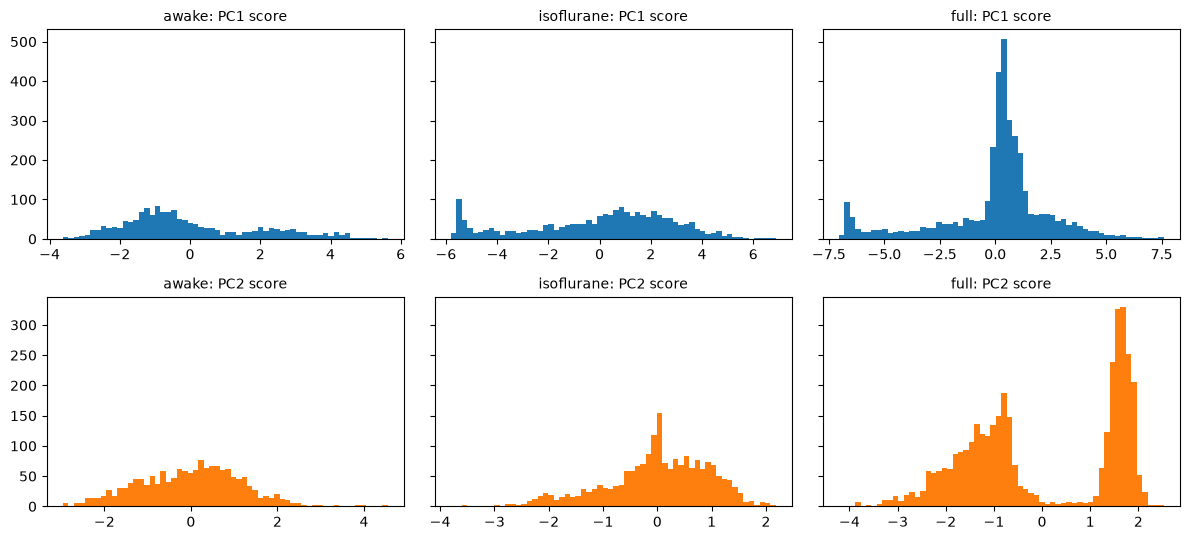

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5), sharey="row")
for c, win in enumerate(WINDOWS):
    scores = fits[win][1]
    for r in (0, 1):
        axes[r, c].hist(scores[:, r], bins=60, color=f"C{r}")
        axes[r, c].set_title(f"{win}: PC{r + 1} score", fontsize=10)
fig.tight_layout()